<a href="https://colab.research.google.com/github/muhdshukri2306-collab/CxL2B-C-Tracker-/blob/main/Summarize_for_CxL2B%2BC_Tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

excel_path = "CxL2B + C Micro Tracker - Qudotech.xlsx"

# Inspect CP (Control Panel) sheet specifically
df_cp = pd.read_excel(excel_path, sheet_name='2B+C CP✅')
print("CP Columns:", df_cp.columns.tolist())
print(df_cp[['Location ', 'Panel Tag/ Asset Tag ', 'Detail', 'Status', 'Done %']])

# Inspect HW Tracker (Hot Water Control Panel & Pumps)
df_hw = pd.read_excel(excel_path, sheet_name='2B+C HW Tracker✅')
print("\nHW Columns:", df_hw.columns.tolist())
print(df_hw[['Panel Tag/ Asset Tag ', 'Detail', 'Status', 'Done %']])

CP Columns: ['Location ', 'Panel Tag/ Asset Tag ', 'Detail', 'Panel Source', 'Link ACC', 'FOAK', 'Status', 'Done %', 'Visual Inspection & Labelling', 'Insulation Resistance Test ', 'Continuity Test', 'Control/ Sensor Test ', 'Earth bonding check', 'Installation Date ', 'CxL2B+C (Test) Date ', 'Energization Date ', 'CxL3A+B Date ', 'Remarks']
    Location                Panel Tag/ Asset Tag   \
0         MYD  SGW1-MY01-PNL-MCP-BOOSTP-01 (FOAK)   
1         MYD          SGW1-MY01-PNL-MCP-MUWTP-01   
2         MYD         SGW1-MY01-PNL-MCP-BOOSTP-02   
3         MYD         SGW1-MY01-PNL-MCP-BOOSTP-03   
4         NaN                                 NaN   
5         NaN                                 NaN   
6         NaN                                 NaN   
7   Location                Panel Tag/ Asset Tag    
8        ODC                  SGW-HUB-PNL-CP-CWBP   
9        ODC                    SGW-HUB-PNL-CP-WC   
10       ODC                   SGW-HUB-PNL-CP-WLC   
11        NaN       

In [16]:
# Analyze individual testing activity parameters across panel sheets
cp_activities = ['Visual Inspection & Labelling', 'Insulation Resistance Test ', 'Continuity Test', 'Control/ Sensor Test ', 'Earth bonding check']

# Extract clean CP rows
df_cp_clean = df_cp[df_cp['Panel Tag/ Asset Tag '].notna() & (~df_cp['Panel Tag/ Asset Tag '].astype(str).str.contains('Tag', na=False))].copy()

activity_summary = {}
for act in cp_activities:
    if act in df_cp_clean.columns:
        activity_summary[act.strip()] = df_cp_clean[act].value_counts().to_dict()

print("Control Panel Testing Sub-activities Breakdown:")
print(pd.DataFrame(activity_summary).fillna(0))

Control Panel Testing Sub-activities Breakdown:
            Visual Inspection & Labelling  Insulation Resistance Test  \
Non-tested                             10                          10   

            Continuity Test  Control/ Sensor Test  Earth bonding check  
Non-tested               10                    10                   10  


In [17]:
df_cp_clean = df_cp[df_cp['Panel Tag/ Asset Tag '].notna() & (~df_cp['Panel Tag/ Asset Tag '].astype(str).str.contains('Tag'))].copy()

activity_summary = {}
for act in cp_activities:
    if act in df_cp_clean.columns:
        activity_summary[act.strip()] = df_cp_clean[act].value_counts().to_dict()

activity_df = pd.DataFrame(activity_summary).fillna(0)
print(activity_df)

            Visual Inspection & Labelling  Insulation Resistance Test  \
Non-tested                             10                          10   

            Continuity Test  Control/ Sensor Test  Earth bonding check  
Non-tested               10                    10                   10  


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Panel Categories and counts
panel_categories = [
    'Main Transfer\nPump MCP',
    'Makeup Water\nTransfer MCP',
    'Potable Water\nBooster MCP',
    'Rainwater\nBooster MCP',
    'Cold Water\nBooster CP',
    'Water Conditioner\nCP',
    'Water Level\nController CP',
    'Hot Water\nPump CP',
    'Air Source Heat\nPump CP'
]
panel_counts = [1, 1, 1, 1, 1, 1, 1, 3, 1]  # Total = 11 panels across project

# Chart 1: Panel Testing Status by Type
bars = ax1.barh(panel_categories, panel_counts, color='#e74c3c', edgecolor='black', alpha=0.85)
ax1.set_xlabel('Number of Panels', fontsize=11, fontweight='bold')
ax1.set_title('Control Panel Testing Progress by Type\n(Current Status: 0% Completed / Not Started)', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlim(0, 4)
ax1.grid(axis='x', linestyle='--', alpha=0.7)

# Add values on bars
for bar in bars:
    width = bar.get_width()
    ax1.text(width + 0.1, bar.get_y() + bar.get_height()/2, f'{int(width)} Panel (0%)',
             va='center', ha='left', fontsize=9, fontweight='bold', color='#c0392b')

# Chart 2: Test Parameters Checklist Status
test_params = [
    'Visual Inspection\n& Labelling',
    'Insulation\nResistance Test',
    'Continuity\nTest',
    'Control / Sensor\nTest',
    'Earth Bonding\nCheck'
]
tested = [0] * len(test_params)
non_tested = [10] * len(test_params)

ax2.bar(test_params, non_tested, color='#34495e', label='Non-tested (100%)', width=0.5)
ax2.bar(test_params, tested, color='#2ecc71', label='Tested (0%)', width=0.5)

ax2.set_ylabel('Number of Control Panels', fontsize=11, fontweight='bold')
ax2.set_title('Sub-Test Verification Progress (10 Key Panels)', fontsize=12, fontweight='bold', pad=12)
ax2.set_ylim(0, 12)
ax2.legend(loc='upper right')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Value annotations
for i, val in enumerate(non_tested):
    ax2.text(i, val + 0.3, f'{val} Non-tested', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('panel_test_progress_summary.png', dpi=300)
plt.close()

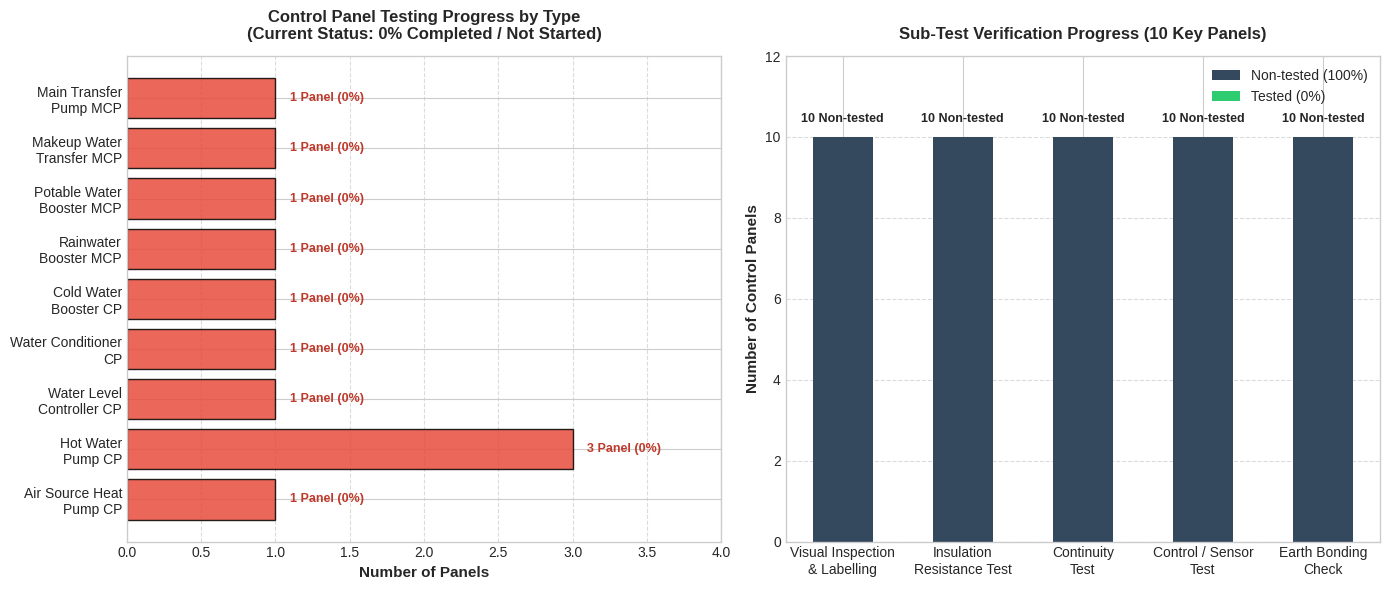

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Set overall plot style
plt.style.use("seaborn-v0_8-whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# -------------------------------------------------------------
# Chart 1: Control Panel Testing Progress by Type (Horizontal Bar)
# -------------------------------------------------------------
panel_categories = [
    "Air Source Heat\nPump CP",
    "Hot Water\nPump CP",
    "Water Level\nController CP",
    "Water Conditioner\nCP",
    "Cold Water\nBooster CP",
    "Rainwater\nBooster MCP",
    "Potable Water\nBooster MCP",
    "Makeup Water\nTransfer MCP",
    "Main Transfer\nPump MCP",
]
panel_counts = [1, 3, 1, 1, 1, 1, 1, 1, 1]  # Total panels = 11

bars = ax1.barh(
    panel_categories,
    panel_counts,
    color="#e74c3c",
    edgecolor="black",
    alpha=0.85,
)
ax1.set_xlabel("Number of Panels", fontsize=11, fontweight="bold")
ax1.set_title(
    "Control Panel Testing Progress by Type\n(Current Status: 0% Completed /"
    " Not Started)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax1.set_xlim(0, 4)
ax1.grid(axis="x", linestyle="--", alpha=0.7)

# Add numeric annotations on each bar
for bar in bars:
  width = bar.get_width()
  ax1.text(
      width + 0.1,
      bar.get_y() + bar.get_height() / 2,
      f"{int(width)} Panel (0%)",
      va="center",
      ha="left",
      fontsize=9,
      fontweight="bold",
      color="#c0392b",
  )

# -------------------------------------------------------------
# Chart 2: Sub-Test Verification Progress (Vertical Bar)
# -------------------------------------------------------------
test_params = [
    "Visual Inspection\n& Labelling",
    "Insulation\nResistance Test",
    "Continuity\nTest",
    "Control / Sensor\nTest",
    "Earth Bonding\nCheck",
]
tested = [0, 0, 0, 0, 0]
non_tested = [10, 10, 10, 10, 10]

ax2.bar(
    test_params,
    non_tested,
    color="#34495e",
    label="Non-tested (100%)",
    width=0.5,
)
ax2.bar(test_params, tested, color="#2ecc71", label="Tested (0%)", width=0.5)

ax2.set_ylabel("Number of Control Panels", fontsize=11, fontweight="bold")
ax2.set_title(
    "Sub-Test Verification Progress (10 Key Panels)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax2.set_ylim(0, 12)
ax2.legend(loc="upper right")
ax2.grid(axis="y", linestyle="--", alpha=0.7)

# Add value labels above the vertical bars
for i, val in enumerate(non_tested):
  ax2.text(
      i,
      val + 0.3,
      f"{val} Non-tested",
      ha="center",
      va="bottom",
      fontsize=9,
      fontweight="bold",
  )

# -------------------------------------------------------------
# Layout Adjustments & Display
# -------------------------------------------------------------
plt.tight_layout()
plt.savefig("panel_test_progress_summary.png", dpi=300)
plt.show()